# 06 — Đánh giá thuật toán ghép bạn ở (Reciprocal Recommender)

Đề tài THS2026-66. Notebook gọi **đúng các hàm thuật toán của sản phẩm** (`apps/api/app/matching/`:
`filters`, `score`, `weights`, `stable`, `simulate`) qua `eval/roommate_lib.py` — không cài lại công thức.

| Mục | Nội dung | Dữ liệu |
|---|---|---|
| 1 | Thực trạng pool theo từng tầng lọc, theo giới | khảo sát thật |
| 2 | Cosine vs Gower (bác ngưỡng SRS FR-5.2 "cosine ≥ 0,7") | khảo sát thật |
| 3 | Harmonic vs trung bình cộng | khảo sát thật |
| 4 | Ablation (cosine/Gower · trọng số · lọc cứng 1/2 tầng · cộng/harmonic) | khảo sát thật |
| 5 | Độ nhạy trọng số ±20% → Kendall τ | khảo sát thật |
| 6 | Đường cong độ phủ theo N | **MÔ PHỎNG** (bootstrap từ khảo sát) |
| 7 | Stable Roommates theo giới | khảo sát thật (+ mô phỏng để so) |
| 8 | Congestion — Gini của exposure | mô phỏng deck + `deck_log` nếu có |
| 9 | P@3 / NDCG@3 / Wilcoxon (chấm làm mù 1–5) | **chờ dữ liệu buổi thử nghiệm** |

**Riêng tư:** `eval/data/survey_v2.csv` có họ tên · MSSV · email. Notebook **không in** bất kỳ trường định danh nào —
hồ sơ thật chỉ mang id âm. Đừng thêm ô in `df.head()` trên CSV gốc.

Chạy: `eval/.venv/bin/jupyter lab eval/notebooks/` (venv riêng — xem `eval/README.md`).

In [1]:
import math, random, statistics, sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent))          # eval/
import metrics as M
import roommate_lib as R
from roommate_lib import F, S, ST, W

pd.set_option("display.precision", 3)
FIG = Path.cwd() / "figs"; FIG.mkdir(exist_ok=True)
SEED = 2026

real = R.load_real()
sims = R.load_sims(24)
print(f"Phản hồi khảo sát: {R.survey_rows()} · hồ sơ dùng được (có giới + phần D): {len(real)}")
print("Theo giới (thật):", dict(Counter(p.gender for p in real)))
print("Hồ sơ mô phỏng:", dict(Counter(p.gender for p in sims)), "(seed", R.SIM.DEFAULT_SEED, ")")

Phản hồi khảo sát: 33 · hồ sơ dùng được (có giới + phần D): 19
Theo giới (thật): {'nam': 13, 'nu': 6}
Hồ sơ mô phỏng: {'nu': 12, 'nam': 12} (seed 2026 )


## 1. Thực trạng pool theo từng tầng lọc

Lọc cứng chạy theo thứ tự `filters.hard_filter_reason`: **an toàn** (cùng giới → deal-breaker cứng hai chiều)
→ **khả thi** (ngân sách lệch > 1 bậc → "ở một mình" → thời điểm cần phòng lệch > 2 tháng).
Mỗi cột là số ứng viên còn lại **sau** tầng đó. *Độ phủ* = tỉ lệ người có ≥ 1 ứng viên.

In [2]:
STAGES = ["cùng giới", "deal-breaker cứng", "ngân sách", "ở một mình", "thời điểm cần phòng"]
REASON_STAGE = {"gender_mismatch": 0, "hard_db_a": 1, "hard_db_b": 1, "budget_gap": 2,
                "scenario_alone": 3, "need_from_gap": 4}

def stage_pools(profiles):
    rows = []
    for a in profiles:
        left = [0] * len(STAGES)
        for b in profiles:
            if a.user_id == b.user_id or a.gender != b.gender:
                continue
            why = F.hard_filter_reason(a, b)
            fail = len(STAGES) if why is None else REASON_STAGE[why.split(":")[0]]
            for s in range(len(STAGES)):
                if fail > s:
                    left[s] += 1
        rows.append({"gender": a.gender, **{STAGES[s]: left[s] for s in range(len(STAGES))}})
    return pd.DataFrame(rows)

sp = stage_pools(real)
summary = []
for g, grp in [("nam", sp[sp.gender == "nam"]), ("nữ", sp[sp.gender == "nu"]), ("tất cả", sp)]:
    summary.append({"giới": g, "n": len(grp),
                    **{f"TB pool sau '{s}'": grp[s].mean() for s in STAGES},
                    "độ phủ cuối": M.coverage_at_least_one(grp[STAGES[-1]].tolist())})
pool_table = pd.DataFrame(summary).set_index("giới")
pool_table

,n,TB pool sau 'cùng giới',TB pool sau 'deal-breaker cứng',TB pool sau 'ngân sách',TB pool sau 'ở một mình',TB pool sau 'thời điểm cần phòng',độ phủ cuối
giới,,,,,,,
nam,13,12.000,8.923,6.769,4.308,3.846,0.769
nữ,6,5.000,5.000,5.000,5.000,4.333,1.000
tất cả,19,9.789,7.684,6.211,4.526,4.000,0.842


In [3]:
cov = pd.DataFrame({s: [M.coverage_at_least_one(sp[sp.gender == g][s]) for g in ("nam", "nu")] + [M.coverage_at_least_one(sp[s])]
                    for s in STAGES}, index=["nam", "nữ", "tất cả"])
print("Độ phủ (≥1 ứng viên) sau từng tầng:")
cov.map(R.pct)

Độ phủ (≥1 ứng viên) sau từng tầng:


,cùng giới,deal-breaker cứng,ngân sách,ở một mình,thời điểm cần phòng
nam,100.0%,100.0%,92.3%,76.9%,76.9%
nữ,100.0%,100.0%,100.0%,100.0%,100.0%
tất cả,100.0%,100.0%,94.7%,84.2%,84.2%


## 2. Cosine vs Gower — vì sao bỏ ngưỡng "Weighted Cosine ≥ 0,7" (SRS FR-5.2)

Các chiều đều dương, thang ngắn ⇒ hai vector thô gần như luôn cùng hướng; cosine bỏ qua độ lớn
(đúng phần "bạn sạch 5, tôi sạch 2"). Đo trên **mọi cặp cùng giới** của hồ sơ thật.

Số cặp cùng giới: 93 (cosine xác định: 93)
Cosine ≥ 0,7     : 91.4% cặp  ← ngưỡng SRS gần như không loại ai
Cosine: min 0.337 · trung vị 0.897 · IQR 0.156
Gower : min 0.134 · trung vị 0.581 · IQR 0.129
Spearman(cosine, Gower) = 0.574


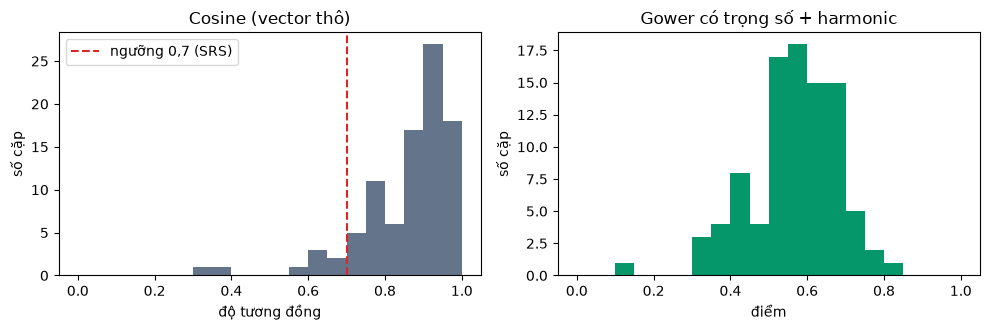

In [4]:
pairs = [(a, b) for i, a in enumerate(real) for b in real[i + 1:] if a.gender == b.gender]
cos = np.array([M.cosine_similarity(R.cosine_vector(a), R.cosine_vector(b)) or np.nan for a, b in pairs])
gow = np.array([S.pair_score(a, b, W.DEFAULT).score for a, b in pairs])
ok = ~np.isnan(cos)
print(f"Số cặp cùng giới: {len(pairs)} (cosine xác định: {ok.sum()})")
print(f"Cosine ≥ 0,7     : {R.pct((cos[ok] >= 0.7).mean())} cặp  ← ngưỡng SRS gần như không loại ai")
print(f"Cosine: min {np.nanmin(cos):.3f} · trung vị {np.nanmedian(cos):.3f} · IQR {np.nanpercentile(cos,75)-np.nanpercentile(cos,25):.3f}")
print(f"Gower : min {gow.min():.3f} · trung vị {np.median(gow):.3f} · IQR {np.percentile(gow,75)-np.percentile(gow,25):.3f}")
rho = stats.spearmanr(cos[ok], gow[ok]).statistic
print(f"Spearman(cosine, Gower) = {rho:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(cos[ok], bins=20, range=(0, 1), color="#64748b"); ax[0].axvline(0.7, color="#dc2626", ls="--", label="ngưỡng 0,7 (SRS)")
ax[0].set_title("Cosine (vector thô)"); ax[0].legend(); ax[0].set_xlabel("độ tương đồng")
ax[1].hist(gow, bins=20, range=(0, 1), color="#059669"); ax[1].set_title("Gower có trọng số + harmonic"); ax[1].set_xlabel("điểm")
for a in ax: a.set_ylabel("số cặp")
fig.tight_layout(); fig.savefig(FIG / "06_cosine_vs_gower.png", dpi=150); plt.show()

## 3. Harmonic mean vs trung bình cộng

Harmonic phạt cặp **một chiều** (A hợp B nhưng B không hợp A): 0,9/0,3 → 0,45 (cộng: 0,60).

In [5]:
har = np.array([S.pair_score(a, b, W.DEFAULT).score for a, b in pairs])
ari = np.array([R.arith_score(a, b, W.DEFAULT) for a, b in pairs])
asym = np.array([abs(S.pair_score(a, b, W.DEFAULT).s_ab - S.pair_score(a, b, W.DEFAULT).s_ba) for a, b in pairs])
lower = (har < ari - 1e-9).sum(); equal = (np.abs(har - ari) <= 1e-9).sum()
print(f"Harmonic < cộng ở {lower}/{len(pairs)} cặp; bằng nhau ở {equal} cặp (chỉ khi s_ab = s_ba)")
print(f"Chênh lệch TB {np.mean(ari - har):.4f} · lớn nhất {np.max(ari - har):.4f}")
print(f"Tương quan (độ lệch hai chiều, mức phạt) = {stats.spearmanr(asym, ari - har).statistic:.3f}  ← phạt tăng theo độ lệch")

Harmonic < cộng ở 84/93 cặp; bằng nhau ở 9 cặp (chỉ khi s_ab = s_ba)
Chênh lệch TB 0.0111 · lớn nhất 0.0624
Tương quan (độ lệch hai chiều, mức phạt) = 0.983  ← phạt tăng theo độ lệch


## 4. Ablation

Mỗi dòng đổi **một** yếu tố so với cấu hình sản phẩm (dòng đầu). Chưa có nhãn ⇒ đo những gì đo được hôm nay:
- **độ phủ** (người có ≥ 1 ứng viên) và **pool TB**;
- **trùng top-3** với cấu hình sản phẩm (Jaccard TB) và **τ thứ hạng** trên các ứng viên chung — cho biết yếu tố đó
  có *đổi gợi ý* hay không. Yếu tố nào tốt hơn thì phải chờ điểm chấm (mục 9).

"Lọc cứng 1 tầng" = coi **mọi** deal-breaker là veto tuyệt đối (thiết kế ban đầu).

*Đọc cột τ:* τ chỉ tính trên các ứng viên **chung** của hai cấu hình. Hai dòng chỉ đổi bộ lọc (không lọc / 1 tầng)
dùng cùng hàm điểm nên τ = 1 là đương nhiên — với chúng, hãy đọc **độ phủ** và **trùng top-3**.

In [6]:
def one_tier(a, b):
    # mọi deal-breaker đều cứng, hai chiều; giữ nguyên các kiểm còn lại
    if a.gender != b.gender or a.user_id == b.user_id or not (a.in_pool and b.in_pool):
        return False
    for x, y in ((a, b), (b, a)):
        if any(F._triggered(db, y) for db in x.deal_breakers):
            return False
    return F.hard_filter_reason(a, b) is None

def cosine_score(a, b, weights=None):
    v = M.cosine_similarity(R.cosine_vector(a), R.cosine_vector(b))
    return -1.0 if v is None else v

VARIANTS = [
    # tên, hàm điểm(a,b), bộ lọc(a,b)
    ("SẢN PHẨM: Gower · khảo sát · lọc 2 tầng · harmonic", lambda a, b: S.pair_score(a, b, W.DEFAULT).score, F.passes_hard_filters),
    ("cosine thay Gower",                                   cosine_score,                                     F.passes_hard_filters),
    ("trọng số đều",                                        lambda a, b: S.pair_score(a, b, W.UNIFORM).score, F.passes_hard_filters),
    ("trung bình cộng thay harmonic",                       lambda a, b: R.arith_score(a, b, W.DEFAULT),     F.passes_hard_filters),
    ("KHÔNG lọc cứng (chỉ cùng giới)",                      lambda a, b: S.pair_score(a, b, W.DEFAULT).score, lambda a, b: a.gender == b.gender and a.user_id != b.user_id and a.in_pool and b.in_pool),
    ("lọc cứng 1 tầng (mọi deal-breaker là veto)",          lambda a, b: S.pair_score(a, b, W.DEFAULT).score, one_tier),
]

def rank_lists(score_fn, filt, profiles, k=None):
    out = {}
    for a in profiles:
        c = [b for b in profiles if b.user_id != a.user_id and filt(a, b)]
        c.sort(key=lambda b: (-score_fn(a, b), b.user_id))
        out[a.user_id] = [b.user_id for b in (c if k is None else c[:k])]
    return out

base_rank = rank_lists(VARIANTS[0][1], VARIANTS[0][2], real)
rows = []
for name, fn, filt in VARIANTS:
    rk = rank_lists(fn, filt, real)
    sizes = [len(v) for v in rk.values()]
    jac, taus = [], []
    for uid, lst in rk.items():
        b3, v3 = set(base_rank[uid][:3]), set(lst[:3])
        if b3 or v3:
            jac.append(len(b3 & v3) / len(b3 | v3))
        common = [x for x in base_rank[uid] if x in set(lst)]
        if len(common) >= 2:
            t = M.kendall_tau([base_rank[uid].index(x) for x in common], [lst.index(x) for x in common])
            if t is not None: taus.append(t)
    rows.append({"cấu hình": name, "độ phủ": M.coverage_at_least_one(sizes), "pool TB": np.mean(sizes),
                 "trùng top-3 (Jaccard)": np.mean(jac) if jac else np.nan,
                 "τ thứ hạng": np.mean(taus) if taus else np.nan})
ablation = pd.DataFrame(rows).set_index("cấu hình")
ablation["độ phủ"] = ablation["độ phủ"].map(R.pct)
ablation

,độ phủ,pool TB,trùng top-3 (Jaccard),τ thứ hạng
cấu hình,,,,
SẢN PHẨM: Gower · khảo sát · lọc 2 tầng · harmonic,84.2%,4.000,1.000,1.000
cosine thay Gower,84.2%,4.000,0.669,0.277
trọng số đều,84.2%,4.000,0.719,0.577
trung bình cộng thay harmonic,84.2%,4.000,0.906,0.903
KHÔNG lọc cứng (chỉ cùng giới),100.0%,9.789,0.426,1.000
lọc cứng 1 tầng (mọi deal-breaker là veto),31.6%,0.421,0.146,1.000


## 5. Độ nhạy trọng số ±20%

Mỗi biến thể tăng/giảm **một** trọng số 20% (`weights.sensitivity`). Với mỗi người: τ giữa thứ hạng gốc và thứ
hạng biến thể trên toàn pool sau lọc, và độ trùng top-5. τ gần 1 ⇒ gợi ý **không** phụ thuộc vào con số trọng số
cụ thể — điều cần chứng minh vì trọng số dẫn từ n = 19.

In [7]:
def ranks_with(weights):
    return rank_lists(lambda a, b: S.pair_score(a, b, weights).score, F.passes_hard_filters, real)

base = ranks_with(W.DEFAULT)
sens = []
for name, wv in W.sensitivity(W.DEFAULT, 0.20):
    rk = ranks_with(wv)
    taus, top5 = [], []
    for uid, lst in base.items():
        if len(lst) >= 2:
            t = M.kendall_tau(list(range(len(lst))), [rk[uid].index(x) for x in lst])
            if t is not None: taus.append(t)
        if lst:
            top5.append(len(set(lst[:5]) & set(rk[uid][:5])) / len(set(lst[:5])))
    sens.append({"biến thể": name, "τ TB": np.mean(taus), "τ min": np.min(taus), "trùng top-5 TB": np.mean(top5)})
sens = pd.DataFrame(sens).set_index("biến thể").sort_values("τ TB")
print(f"τ trung bình trên mọi biến thể: {sens['τ TB'].mean():.3f} · tệ nhất: {sens['τ min'].min():.3f} ({sens['τ min'].idxmin()})")
sens.head(8)

τ trung bình trên mọi biến thể: 0.974 · tệ nhất: 0.600 (sleep_time_up)


,τ TB,τ min,trùng top-5 TB
biến thể,,,
share_stuff_up,0.921,0.619,0.988
money_style_down,0.928,0.667,0.988
deal_breaker_soft_down,0.937,0.667,1.000
sleep_time_up,0.952,0.600,0.988
ac_usage_down,0.954,0.667,0.988
don_vi_up,0.971,0.667,1.000
share_stuff_down,0.973,0.733,1.000
noise_down,0.974,0.800,1.000


## 6. Đường cong độ phủ theo N — **MÔ PHỎNG**

> **Giả định:** người tham gia mới có cùng phân bố lối sống với 19 hồ sơ khảo sát. Pool N lấy mẫu **có hoàn lại** từ
> hồ sơ thật (bootstrap), 200 lần lặp mỗi N. Đây không phải số đo trên người thật.

Thêm số match kỳ vọng với tỉ lệ "quan tâm" mỗi chiều r = 0,3 (thiết kế 3.5): E = pool·r², P(không match) = (1−r²)^pool.

Trần độ phủ = 89.5%: người khai 'ở một mình' bị lọc với MỌI người (filters.py mục 4) nên N lớn đến đâu cũng không được ghép — đúng ý họ.


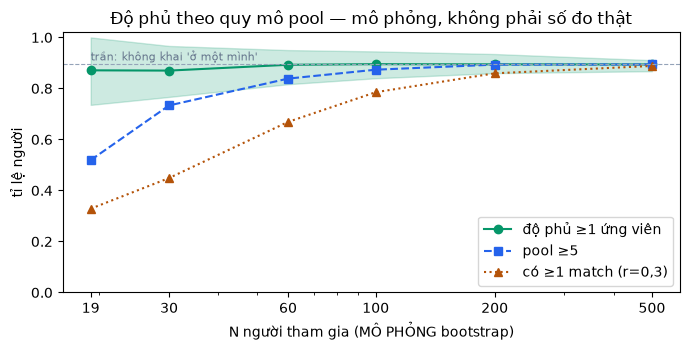

,lần lặp,độ phủ ≥1,CI95 thấp,CI95 cao,pool ≥5,pool trung vị,"P(không match nào), r=0,3"
N,,,,,,,
19,200,0.871,0.736,1.000,0.519,5.045,0.672
30,200,0.870,0.767,0.967,0.733,8.025,0.551
60,200,0.893,0.817,0.950,0.839,17.038,0.331
100,100,0.895,0.840,0.945,0.874,28.735,0.215
200,40,0.895,0.860,0.935,0.893,60.212,0.141
500,12,0.894,0.868,0.911,0.894,148.083,0.112


In [8]:
r = 0.3
NS = [19, 30, 60, 100, 200, 500]
REPS = {19: 200, 30: 200, 60: 200, 100: 100, 200: 40, 500: 12}
curve = []
rng = random.Random(SEED)
for n in NS:
    cov_s, med_s, p5_s, nomatch_s = [], [], [], []
    for _ in range(REPS[n]):
        pool = R.bootstrap_pool(real, n, rng)
        sizes = list(R.pool_sizes(pool).values())
        cov_s.append(M.coverage_at_least_one(sizes)); med_s.append(np.median(sizes))
        p5_s.append(np.mean([s >= 5 for s in sizes]))
        nomatch_s.append(np.mean([(1 - r * r) ** s for s in sizes]))
    curve.append({"N": n, "lần lặp": REPS[n], "độ phủ ≥1": np.mean(cov_s),
                  "CI95 thấp": np.percentile(cov_s, 2.5), "CI95 cao": np.percentile(cov_s, 97.5),
                  "pool ≥5": np.mean(p5_s), "pool trung vị": np.mean(med_s),
                  "P(không match nào), r=0,3": np.mean(nomatch_s)})
curve = pd.DataFrame(curve).set_index("N")
print(f"Trần độ phủ = {R.pct(np.mean([p.scenario != F.SCENARIO_ALONE for p in real]))}: người khai 'ở một mình' "
      "bị lọc với MỌI người (filters.py mục 4) nên N lớn đến đâu cũng không được ghép — đúng ý họ.")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curve.index, curve["độ phủ ≥1"], "o-", label="độ phủ ≥1 ứng viên", color="#059669")
ax.fill_between(curve.index, curve["CI95 thấp"], curve["CI95 cao"], alpha=0.2, color="#059669")
ax.plot(curve.index, curve["pool ≥5"], "s--", label="pool ≥5", color="#2563eb")
ax.plot(curve.index, 1 - curve["P(không match nào), r=0,3"], "^:", label="có ≥1 match (r=0,3)", color="#b45309")
ax.set_xscale("log"); ax.set_xticks(NS); ax.set_xticklabels(NS); ax.set_ylim(0, 1.02)
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ceiling = np.mean([p.scenario != F.SCENARIO_ALONE for p in real])
ax.axhline(ceiling, color="#94a3b8", lw=0.8, ls="--"); ax.text(NS[0], ceiling + 0.015, "trần: không khai 'ở một mình'", fontsize=8, color="#64748b")
ax.set_xlabel("N người tham gia (MÔ PHỎNG bootstrap)"); ax.set_ylabel("tỉ lệ người"); ax.legend(loc="lower right")
ax.set_title("Độ phủ theo quy mô pool — mô phỏng, không phải số đo thật")
fig.tight_layout(); fig.savefig(FIG / "06_coverage_curve.png", dpi=150); plt.show()
curve

## 7. Stable Roommates (Irving 1985) theo giới

Ghép phòng là bài toán **không hai phía** ⇒ có thể **vô nghiệm**. Khi vô nghiệm, `stable.py` trả ghép tham lam kèm
số blocking pair ("almost-stable"). Preference = điểm **có hướng** s(x→y) trên pool sau lọc cứng.

In [9]:
rows = []
for label, prof in [("thật", real), ("thật + mô phỏng", real + sims)]:
    for g in ("nam", "nu"):
        grp = [p for p in prof if p.gender == g]
        res = ST.stable_roommates(grp, W.DEFAULT)
        rows.append({"pool": label, "giới": "nữ" if g == "nu" else g, "n": len(grp), "có ghép ổn định": res.stable,
                     "số cặp": len(res.matching) // 2, "blocking pair": len(res.blocking_pairs),
                     "chưa ghép": len(res.unmatched), "phương pháp": res.method})
pd.DataFrame(rows)

,pool,giới,n,có ghép ổn định,số cặp,blocking pair,chưa ghép,phương pháp
0,thật,nam,13,False,5,2,3,greedy (khong ton tai ghep on dinh)
1,thật,nữ,6,True,3,0,0,irving+exact
2,thật + mô phỏng,nam,25,False,10,1,5,greedy (khong ton tai ghep on dinh)
3,thật + mô phỏng,nữ,18,True,9,0,0,irving+exact


## 8. Congestion — Gini của exposure

Exposure = số deck (của người khác) mà một hồ sơ xuất hiện. Mô phỏng: mỗi người thật lần lượt nhận deck 5 thẻ
từ pool thật + mô phỏng, **có** và **không** có phạt exposure (`exposure_penalty = 0,02`/lần đã hiện — đúng
`matching/repo.py:deck`). Gini → 1 nghĩa là vài hồ sơ "trung tính" hứng hết.

Nếu có `eval/data/deck_log.csv` (xuất từ DB, lệnh bên dưới) thì tính thêm Gini trên log thật.

In [10]:
def sim_exposure(profiles, viewers, k=5, penalty=0.0):
    expo = Counter()
    for v in viewers:
        c = [p for p in profiles if p.user_id != v.user_id and F.passes_hard_filters(v, p)]
        c.sort(key=lambda p: (-(S.pair_score(v, p, W.DEFAULT).score - penalty * expo[p.user_id]), p.user_id))
        for p in c[:k]:
            expo[p.user_id] += 1
    return [expo[p.user_id] for p in profiles]

everyone = real + sims
g0 = M.gini(sim_exposure(everyone, real, penalty=0.0))
g1 = M.gini(sim_exposure(everyone, real, penalty=0.02))
g_real = M.gini(sim_exposure(real, real, penalty=0.02))
print(f"Gini exposure (thật+mô phỏng, KHÔNG phạt) : {g0:.3f}")
print(f"Gini exposure (thật+mô phỏng, phạt 0,02)  : {g1:.3f}")
print(f"Gini exposure (chỉ hồ sơ thật, phạt 0,02) : {g_real:.3f}")

if R.DECK_LOG_CSV.exists():
    dl = pd.read_csv(R.DECK_LOG_CSV)
    per_target = dl.groupby("target_id")["user_id"].nunique()
    print(f"deck_log thật: {len(dl)} dòng · {per_target.size} hồ sơ được hiện · Gini = {M.gini(per_target.tolist()):.3f}")
else:
    print("Chưa có eval/data/deck_log.csv — xuất bằng:")
    print("  docker compose exec -T db psql -U nckh -d nckh -c \"\\copy (SELECT user_id, target_id, position, deck_mode, explore, served_at FROM deck_log) TO STDOUT CSV HEADER\" > eval/data/deck_log.csv")

Gini exposure (thật+mô phỏng, KHÔNG phạt) : 0.430
Gini exposure (thật+mô phỏng, phạt 0,02)  : 0.367
Gini exposure (chỉ hồ sơ thật, phạt 0,02) : 0.314
Chưa có eval/data/deck_log.csv — xuất bằng:
  docker compose exec -T db psql -U nckh -d nckh -c "\copy (SELECT user_id, target_id, position, deck_mode, explore, served_at FROM deck_log) TO STDOUT CSV HEADER" > eval/data/deck_log.csv


## 9. P@3 / NDCG@3 / Wilcoxon — **chờ dữ liệu buổi thử nghiệm**

Thiết kế 2.7: mỗi người chấm 1–5 cho **5 thẻ làm mù** = 3 thẻ top của thuật toán (`arm='algo'`) + 2 ngẫu nhiên trong
pool (`arm='random'`), thứ tự xáo trộn, không hiện %. Thu bằng trang `/roommate/rate`, xuất:

```bash
docker compose exec -T api python -m app.matching.export_ratings > eval/data/ratings.csv
```

Schema cố định (xem `export_ratings.py`): `rater_id, round, card_code, target_id, arm, algo_rank, display_pos, score,
s_ab, s_ba, weights_ver, target_is_simulated, rater_is_simulated, rating, served_at, rated_at`.

- **P@3** = tỉ lệ thẻ thuật toán được chấm ≥ 4. **NDCG@3** = thứ tự `algo_rank` so với thứ tự lý tưởng theo điểm chấm
  trên cả 5 thẻ (gain = rating − 1).
- **Wilcoxon ghép cặp**: điểm TB nhóm `algo` vs nhóm `random` của từng người (đối chiếu với `scipy`).
- Loại người chấm là hồ sơ mô phỏng; báo riêng có/không thẻ mô phỏng.

In [11]:
def evaluate_ratings(df):
    df = df[(df.rater_is_simulated == 0) & df.rating.notna()].copy()
    out = {}
    for label, d in [("mọi thẻ", df), ("chỉ thẻ hồ sơ thật", df[df.target_is_simulated == 0])]:
        p3, nd, algo_m, rand_m = [], [], [], []
        for _, g in d.groupby(["rater_id", "round"]):
            a, rnd = g[g.arm == "algo"].sort_values("algo_rank"), g[g.arm == "random"]
            if len(a) == 0 or len(rnd) == 0:
                continue
            p3.append((a.rating >= 4).mean())
            rel = dict(zip(g.target_id, g.rating - 1))
            nd.append(M.ndcg_at_k(list(a.target_id), rel, k=3))
            algo_m.append(a.rating.mean()); rand_m.append(rnd.rating.mean())
        wx = M.wilcoxon_signed_rank(algo_m, rand_m)
        ref = stats.wilcoxon(algo_m, rand_m, zero_method="wilcox", correction=False, method="approx") if wx["n"] else None
        if ref is not None and wx["p_two_sided"] is not None:
            assert abs(ref.pvalue - wx["p_two_sided"]) < 1e-9, "metrics.wilcoxon lệch scipy — dừng"
        out[label] = {"người chấm": len(p3), "P@3": np.mean(p3) if p3 else np.nan,
                      "NDCG@3": np.mean(nd) if nd else np.nan,
                      "TB algo": np.mean(algo_m) if algo_m else np.nan, "TB random": np.mean(rand_m) if rand_m else np.nan,
                      "Wilcoxon n (≠0)": wx["n"], "p (hai phía)": wx["p_two_sided"], "r": wx["r"]}
    return pd.DataFrame(out).T

if R.RATINGS_CSV.exists():
    ratings = pd.read_csv(R.RATINGS_CSV)
    print(f"ratings.csv: {len(ratings)} thẻ · {ratings.rater_id.nunique()} người · đã chấm {ratings.rating.notna().sum()}")
    display(evaluate_ratings(ratings))
else:
    print("⚠ CHƯA CÓ eval/data/ratings.csv — mục 9 chưa có số thật.")

⚠ CHƯA CÓ eval/data/ratings.csv — mục 9 chưa có số thật.


### 9b. Kiểm tra khung tính — **DỮ LIỆU GIẢ, KHÔNG DÙNG CHO BÁO CÁO**

Ô dưới sinh ngẫu nhiên điểm chấm cho 20 người (nhóm `algo` được cộng thêm 0,7 điểm) **chỉ để chứng minh pipeline ở
mục 9 chạy đúng** trước buổi thử nghiệm. Mọi con số ở đây là **giả**.

In [12]:
rng = np.random.default_rng(SEED)
fake = []
for rid in range(1, 21):
    for pos, (arm, rank) in enumerate([("algo", 1), ("algo", 2), ("algo", 3), ("random", None), ("random", None)]):
        base_r = 3.4 if arm == "algo" else 2.7
        fake.append({"rater_id": rid, "round": 1, "card_code": f"F{rid}{pos}", "target_id": 1000 * rid + pos,
                     "arm": arm, "algo_rank": rank, "display_pos": pos, "target_is_simulated": 0,
                     "rater_is_simulated": 0, "rating": int(np.clip(round(rng.normal(base_r, 1.0)), 1, 5))})
print("DỮ LIỆU GIẢ — chỉ kiểm tra code:")
evaluate_ratings(pd.DataFrame(fake))

DỮ LIỆU GIẢ — chỉ kiểm tra code:


,người chấm,P@3,NDCG@3,TB algo,TB random,Wilcoxon n (≠0),p (hai phía),r
mọi thẻ,20.0,0.417,0.87,3.4,2.8,20.0,0.006,0.615
chỉ thẻ hồ sơ thật,20.0,0.417,0.87,3.4,2.8,20.0,0.006,0.615


## Ghi chú cho Chương 4

- Mục 1–5, 7 đo trên **19 hồ sơ khảo sát thật** (n nhỏ — nêu rõ). Mục 6 là **mô phỏng**. Mục 9b là **dữ liệu giả**.
- Hồ sơ mô phỏng (`is_simulated`) chỉ dùng cho mục 7–8 để so, **không** vào số liệu chính.
- Học trọng số từ swipe (hồi quy logistic, L2, leave-one-user-out CV, AUC ± CI) — **chỉ làm sau buổi thử nghiệm**
  (thiết kế 3.4); đưa ≤ 5–6 chiều vào mô hình.